# Tái lập Thực nghiệm Bài báo & Khảo sát Tham số Error Tolerance ($r$)

Notebook này tái lập đầy đủ các thực nghiệm trong **Mục 4** của bài báo **"KNN Model-Based Approach in Classification"** (*Gongde Guo, Hui Wang, David Bell, Yaxin Bi, Kieran Greer, 2003*), tập trung vào tham số **Error-Tolerant Degree ($r$)** và đối chiếu định lượng với số liệu gốc (đáp ứng yêu cầu Mục 1.2.1 – 1.2.3 của đồ án CSC14005).

### Phạm vi thực nghiệm trong notebook:
1. **Môi trường & Thiết lập tái lập**: Cố định hạt giống ngẫu nhiên (`random_state=42`), chuẩn hóa cục bộ theo từng fold (không data leakage), ghi nhận phiên bản thư viện & phần cứng.
2. **Table 2 & Table 3**: So sánh `C5.0`, `kNNModel (r=1, N>1..N>5)` và `Standard kNN (k=1, 3, 5)` về Accuracy (%), số lượng đại diện và Reduction Rate (%) — bao gồm cả cách tính **per-fold (macro-average)** lẫn **full-dataset (micro-average)** để lý giải chính xác độ lệch với bài báo.
3. **Table 4 (*The influence of $r$ and $N$ to kNNModel*)**: Tìm kiếm trên lưới $(r, N) \in \{1..10\} \times \{1..10\}$ trên cả 6 bộ dữ liệu, kèm bản đồ nhiệt (heatmap) trực quan.
4. **Table 5 (*C5.0 vs kNNModel with model pruning vs kNN*)**: Đối chiếu chính xác cấu hình **Pruning 1 (`r=0, N=1`)** với cấu hình không cắt tỉa (`r=0, N=0`) và kết quả gốc của bài báo.
5. **Fig. 13 (`Aust`) & Fig. 14 (`Glass`) + Mở rộng khảo sát $r \in [0, 15]$ trên cả 6 datasets** (bao gồm `Diabetes`, đồng thời ghi chú lỗi đánh máy ở trang 10 của bài báo gốc).
6. **Kiểm tra độ ổn định**: Đánh giá lại bằng `RepeatedStratifiedKFold (10x5-fold)` và khảo sát ảnh hưởng của bước chọn đặc trưng Information Gain (`k`).

### Các điểm khác biệt so với bài báo gốc cần ghi rõ trong báo cáo:
- **Tiền xử lý**: Bài báo nêu có chuẩn hóa (normalization) và chọn đặc trưng bằng Information Gain nhưng **không công bố** số đặc trưng giữ lại $k$ cũng như cách mã hóa thuộc tính danh nghĩa (`Heart`, `Aust`). Mặc định ở đây giữ toàn bộ đặc trưng (`k="all"`) và chuẩn hóa `MinMaxScaler` cục bộ theo fold (`use_ohe=False`; ảnh hưởng của One-Hot Encoding được phân tích chuyên sâu ở `exp_r0_and_datatype.ipynb`).
- **Baseline C5.0**: Bài báo dùng C5.0 trong phần mềm thương mại *Clementine*; nhóm thay thế bằng `DecisionTreeClassifier(criterion="entropy")` trong `scikit-learn` (không có hậu cắt tỉa/boosting đặc thù của C5.0).
- **Chi tiết cài đặt `pending_errors` trong `knn_model.py`**: Chỉ gộp các điểm lỗi vào hình cầu nếu phía ngoài còn ít nhất 1 điểm cùng lớp chưa grouped (giúp tránh phình bán kính vô ích để nuốt điểm nhiễu ở biên).

In [1]:
import platform
import sys
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from sklearn.feature_selection import SelectKBest
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler

# Tự động định vị thư mục Source
source_path = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_loader.py").exists()),
    Path.cwd().parent.parent,
)
if str(source_path) not in sys.path:
    sys.path.append(str(source_path))

from data_loader import DATASETS, _information_gain, load_dataset, make_preprocessor
from knn_model import KNNModel
from baseline.standard_knn import StandardKNN, get_standard_knn
from baseline.c50 import C50Classifier, get_c50

SEED = 42
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
plt.rcParams["figure.dpi"] = 110

print("=== THÔNG TIN MÔI TRƯỜNG THỰC NGHIỆM (REPRODUCIBILITY) ===")
print(f"Source path   : {source_path}")
print(f"OS / Platform : {platform.platform()}")
print(f"Python        : {sys.version.split()[0]}")
print(f"NumPy         : {np.__version__}")
print(f"SciPy         : {scipy.__version__}")
print(f"scikit-learn  : {sklearn.__version__}")
print(f"pandas        : {pd.__version__}")
print(f"matplotlib    : {matplotlib.__version__}")
print(f"CV / Seed     : StratifiedKFold(n_splits=5, shuffle=True, random_state={SEED})")
print(f"Datasets      : {DATASETS}")

=== THÔNG TIN MÔI TRƯỜNG THỰC NGHIỆM (REPRODUCIBILITY) ===
Source path   : d:\US\ML-Project\Source
OS / Platform : Windows-10-10.0.19045-SP0
Python        : 3.14.5
NumPy         : 2.5.5
SciPy         : 1.18.1
scikit-learn  : 1.9.1
pandas        : 3.1.1
matplotlib    : 3.11.2
CV / Seed     : StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
Datasets      : ('glass', 'iris', 'heart', 'wine', 'diabetes', 'aust')


In [2]:
# === SỐ LIỆU GỐC TỪ BÀI BÁO GUO ET AL. (2003) ĐỂ ĐỐI CHIẾU ===
PAPER_TABLE2 = pd.DataFrame(
    {
        "C5.0": [66.30, 92.00, 75.60, 92.10, 76.60, 85.50],
        "N>1": [70.95, 96.00, 80.37, 96.00, 73.59, 85.65],
        "N>2": [70.95, 96.00, 80.37, 96.00, 73.59, 85.65],
        "N>3": [70.00, 96.00, 80.74, 96.00, 73.86, 85.07],
        "N>4": [68.57, 96.00, 80.37, 96.00, 74.25, 84.93],
        "N>5": [67.62, 96.00, 81.11, 96.00, 75.42, 84.93],
        "K=1": [67.14, 95.33, 75.93, 96.57, 68.24, 82.17],
        "K=3": [70.48, 94.67, 80.74, 95.43, 73.59, 86.23],
        "K=5": [68.10, 95.33, 82.96, 94.86, 74.38, 86.38],
    },
    index=["Glass", "Iris", "Heart", "Wine", "Diabetes", "Aust"],
)
PAPER_TABLE2.loc["Average"] = PAPER_TABLE2.mean()

PAPER_TABLE3_REPS = pd.DataFrame(
    {
        "N>1": [31, 5, 26, 8, 106, 54],
        "N>2": [31, 5, 26, 8, 106, 54],
        "N>3": [24, 4, 22, 8, 94, 49],
        "N>4": [18, 4, 21, 7, 78, 44],
        "N>5": [13, 4, 19, 7, 59, 41],
        "kNN (Total)": [214, 150, 270, 178, 768, 690],
    },
    index=["Glass", "Iris", "Heart", "Wine", "Diabetes", "Aust"],
)
PAPER_TABLE3_RR_MICRO = pd.Series(
    {"N>1": 89.87, "N>2": 89.87, "N>3": 91.15, "N>4": 92.42, "N>5": 93.70}
)

PAPER_TABLE4 = pd.DataFrame(
    {
        "Paper Best Acc%": [70.95, 96.00, 83.70, 96.00, 77.12, 87.10],
        "Paper r": [1, 1, 3, 1, 5, 2],
        "Paper N": [1, 1, 3, 1, 3, 1],
    },
    index=["Glass", "Iris", "Heart", "Wine", "Diabetes", "Aust"],
)

PAPER_TABLE5 = pd.DataFrame(
    {
        "Paper C5.0 CA%": [66.30, 92.00, 75.60, 92.10, 76.60, 85.50],
        "Paper kNNModel(r=0) CA%": [68.57, 95.33, 80.74, 95.43, 74.77, 86.09],
        "Paper kNNModel(r=0) RR%": [82.71, 95.33, 89.26, 94.94, 86.32, 93.91],
        "Paper kNN CA%": [68.57, 95.11, 79.88, 95.62, 72.07, 84.93],
    },
    index=["Glass", "Iris", "Heart", "Wine", "Diabetes", "Aust"],
)
PAPER_TABLE5.loc["Average"] = PAPER_TABLE5.mean()


def build_preprocessor(
    k: int | str = "all",
    use_ohe: bool = False,
    dataset_name: str | None = None,
) -> Pipeline:
    """Tạo pipeline tiền xử lý cục bộ theo từng fold."""
    if use_ohe:
        if dataset_name is None:
            raise ValueError("Cần truyền dataset_name khi use_ohe=True.")
        return make_preprocessor(dataset_name, k=k)

    steps = [
        ("impute", SimpleImputer(strategy="median")),
        ("scale", MinMaxScaler()),
    ]
    if k != "all":
        steps.append(("select", SelectKBest(score_func=_information_gain, k=k)))
    return Pipeline(steps)


def evaluate_model(
    dataset_name: str,
    clf,
    k: int | str = "all",
    use_ohe: bool = False,
    cv=CV,
) -> dict:
    """Chạy CV và trả về Accuracy (%), std, số đại diện trung bình và Reduction Rate (%)."""
    X, y = load_dataset(dataset_name)
    pipe = Pipeline([
        ("prep", build_preprocessor(k=k, use_ohe=use_ohe, dataset_name=dataset_name)),
        ("clf", clf),
    ])

    is_knn_model = isinstance(clf, KNNModel)
    res = cross_validate(
        pipe, X, y, cv=cv, scoring="accuracy", return_estimator=is_knn_model
    )

    out = {
        "acc_mean": float(res["test_score"].mean() * 100),
        "acc_std": float(res["test_score"].std() * 100),
        "avg_reps": np.nan,
        "avg_train_n": np.nan,
        "rr_mean": 0.0,
    }

    if is_knn_model:
        estimators = [est.named_steps["clf"] for est in res["estimator"]]
        out["avg_reps"] = float(np.mean([e.n_representatives_ for e in estimators]))
        out["avg_train_n"] = float(np.mean([e.n_train_samples_ for e in estimators]))
        out["rr_mean"] = float(np.mean([e.reduction_rate_ for e in estimators]))

    return out


def fit_full_dataset_reps(
    dataset_name: str,
    r: int = 1,
    N: int = 1,
    k: int | str = "all",
    use_ohe: bool = False,
) -> tuple[int, float]:
    """Huấn luyện trên 100% tập dữ liệu để đối chiếu số đại diện nguyên & micro-RR như Table 3 bài báo."""
    X, y = load_dataset(dataset_name)
    prep = build_preprocessor(k=k, use_ohe=use_ohe, dataset_name=dataset_name)
    X_t = prep.fit_transform(X, y)
    model = KNNModel(r=r, N=N, metric="euclidean").fit(X_t, y)
    return model.n_representatives_, float(model.reduction_rate_)


def _finalize_knn_model(r: int, N: int, reps, classes, n_train_samples: int) -> KNNModel:
    """Khởi tạo đầy đủ thuộc tính đã fit cho KNNModel giống hệt KNNModel.fit()."""
    m = KNNModel(r=r, N=N, metric="euclidean")
    m.classes_ = classes
    m.n_train_samples_ = n_train_samples
    m.representatives_ = reps
    m.n_representatives_ = len(reps)
    m.reduction_rate_ = (
        (1.0 - m.n_representatives_ / n_train_samples) * 100.0
        if n_train_samples > 0
        else 0.0
    )
    m._rep_centers_ = np.array([rep.rep for rep in reps], dtype=np.float64)
    m._rep_sims_ = np.array([rep.sim for rep in reps], dtype=np.float64)
    return m


def evaluate_r_N_grid_fast(
    dataset_name: str,
    r_values=range(1, 11),
    n_values=range(1, 11),
    k: int | str = "all",
    use_ohe: bool = False,
    cv=CV,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Đánh giá lưới (r, N) chính xác từng bit so với KNNModel(r, N) nhưng tái sử dụng Pass 1
    (initial_reps) và cache các mặt nạ cắt tỉa trùng nhau để tăng tốc 5x–8x.
    """
    X, y = load_dataset(dataset_name)
    r_list = list(r_values)
    n_list = list(n_values)

    acc_folds = {(r, n): [] for r in r_list for n in n_list}
    rr_folds = {(r, n): [] for r in r_list for n in n_list}

    helper = KNNModel(metric="euclidean")

    for train_idx, test_idx in cv.split(X, y):
        prep = build_preprocessor(k=k, use_ohe=use_ohe, dataset_name=dataset_name)
        X_train = np.asarray(prep.fit_transform(X[train_idx], y[train_idx]), dtype=np.float64)
        X_test = np.asarray(prep.transform(X[test_idx]), dtype=np.float64)
        y_train, y_test = np.asarray(y[train_idx]), np.asarray(y[test_idx])
        classes = np.unique(y_train)
        n_train = len(X_train)

        for r in r_list:
            initial_reps = helper._build_model(X_train, y_train, r=r)
            retrain_cache: dict[bytes, list] = {}
            eval_cache: dict[int, tuple[float, float]] = {}

            for n_val in n_list:
                if n_val == 0:
                    reps = initial_reps
                else:
                    weak_mask = np.zeros(n_train, dtype=bool)
                    has_pruned = False
                    for rep in initial_reps:
                        if rep.num <= n_val:
                            has_pruned = True
                            weak_mask[rep.member_indices] = True

                    if has_pruned:
                        keep_mask = ~weak_mask
                        if np.any(keep_mask):
                            mask_key = keep_mask.tobytes()
                            if mask_key not in retrain_cache:
                                retrain_cache[mask_key] = helper._build_model(
                                    X_train[keep_mask], y_train[keep_mask], r=r
                                )
                            reps = retrain_cache[mask_key]
                        else:
                            reps = initial_reps
                    else:
                        reps = initial_reps

                reps_id = id(reps)
                if reps_id not in eval_cache:
                    m = _finalize_knn_model(r, n_val, reps, classes, n_train)
                    acc = float(accuracy_score(y_test, m.predict(X_test)) * 100.0)
                    eval_cache[reps_id] = (acc, float(m.reduction_rate_))

                acc, rr = eval_cache[reps_id]
                acc_folds[(r, n_val)].append(acc)
                rr_folds[(r, n_val)].append(rr)

    df_acc = pd.DataFrame(index=r_list, columns=n_list, dtype=float)
    df_rr = pd.DataFrame(index=r_list, columns=n_list, dtype=float)
    df_acc.index.name = "r"
    df_acc.columns.name = "N"
    df_rr.index.name = "r"
    df_rr.columns.name = "N"
    for r in r_list:
        for n_val in n_list:
            df_acc.loc[r, n_val] = float(np.mean(acc_folds[(r, n_val)]))
            df_rr.loc[r, n_val] = float(np.mean(rr_folds[(r, n_val)]))
    return df_acc, df_rr


def plot_knn_r_curve(
    x,
    y,
    title: str = "",
    ylim=None,
    figsize=(7.5, 3.2),
):
    """Vẽ biểu đồ Accuracy theo r theo phong cách Fig. 13 & 14 của bài báo."""
    fig, ax = plt.subplots(figsize=figsize, facecolor="white")
    ax.set_facecolor("#D8D8D8")

    ax.plot(
        x, y,
        color="#000080",
        marker="D",
        markersize=4.5,
        linewidth=1.5,
        zorder=3,
    )

    # Đánh dấu điểm cực đại
    best_idx = int(np.argmax(y))
    ax.scatter([x[best_idx]], [y[best_idx]], color="#d62728", s=55, zorder=4)
    ax.annotate(
        f"Best: r={x[best_idx]} ({y[best_idx]:.2f}%)",
        xy=(x[best_idx], y[best_idx]),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=8.5,
        fontweight="bold",
        color="#8B0000",
    )

    ax.yaxis.grid(True, color="black", linestyle="-", linewidth=0.6, alpha=0.6, zorder=0)
    ax.xaxis.grid(False)

    ax.set_xticks(x)
    ax.set_xlim(min(x) - 0.5, max(x) + 0.5)
    ax.set_xlabel("Error Tolerant Degree $r$", fontsize=11, labelpad=6)
    ax.set_ylabel("Accuracy (%)", fontsize=11)

    if title:
        ax.set_title(title, fontsize=11, fontweight="bold", pad=10)
    if ylim is not None:
        ax.set_ylim(ylim)

    ax.tick_params(axis="both", direction="out", length=4, width=1, colors="black")
    for spine in ax.spines.values():
        spine.set_color("black")
        spine.set_linewidth(0.8)

    fig.patch.set_edgecolor("black")
    fig.patch.set_linewidth(1.2)
    plt.tight_layout(pad=1.4)
    plt.show()

---
## Phần 1: Tái lập Table 2 & Table 3 (So sánh `C5.0`, `kNNModel (r=1, N>1..5)`, `Standard kNN`)

**Lưu ý kỹ thuật khi đối chiếu Table 3 với bài báo gốc:**
- Trong bài báo (Table 3, trang 9), số lượng đại diện đều là số nguyên (vd: Glass = 31, Diabetes = 106, tổng cộng 230 đại diện trên tổng 2.270 mẫu ở `N>1`) và tỷ lệ nén trung bình là **micro-average**: $1 - 230 / 2270 = 89.87\%$ (tương tự `N>3`: $1 - 201/2270 = 91.15\%$, `N>4`: $1 - 172/2270 = 92.42\%$, `N>5`: $1 - 143/2270 = 93.70\%$). Điều này cho thấy bài báo báo cáo số đại diện khi xây mô hình trên **100% tập dữ liệu**.
- Do đó, dưới đây ta xuất đồng thời cả **Table 3a (trung bình theo từng fold 80% dữ liệu, đặt cạnh `kNN (Train/Fold)`)** và **Table 3b (huấn luyện trên 100% dữ liệu + Micro-Average RR%)** để so sánh công bằng với bài báo.

In [3]:
table2_rows = []
table3_fold_reps_rows = []
table3_fold_rr_rows = []
table3_full_reps_rows = []

FEATURE_K = {ds: "all" for ds in DATASETS}

for ds in DATASETS:
    X, _ = load_dataset(ds)
    k_feat = FEATURE_K[ds]
    ds_title = ds.capitalize()

    row_acc = {"Dataset": ds_title}
    row_fold_reps = {"Dataset": ds_title}
    row_fold_rr = {"Dataset": ds_title}
    row_full_reps = {"Dataset": ds_title}

    # Baseline 2: C5.0
    row_acc["C5.0"] = evaluate_model(ds, get_c50(), k=k_feat)["acc_mean"]

    # KNNModel với r=1 và N > 1..5 (tương ứng N = 1..5 trong KNNModel)
    avg_train_n = np.nan
    for n_val in range(1, 6):
        col = f"N>{n_val}"
        metrics = evaluate_model(ds, KNNModel(r=1, N=n_val, metric="euclidean"), k=k_feat)
        row_acc[col] = metrics["acc_mean"]
        row_fold_reps[col] = metrics["avg_reps"]
        row_fold_rr[col] = metrics["rr_mean"]
        avg_train_n = metrics["avg_train_n"]

        full_reps, _ = fit_full_dataset_reps(ds, r=1, N=n_val, k=k_feat)
        row_full_reps[col] = full_reps

    row_fold_reps["kNN (Train/Fold)"] = avg_train_n
    row_full_reps["kNN (Total)"] = len(X)

    # Baseline 1: Standard k-NN (k = 1, 3, 5)
    for k_nn in (1, 3, 5):
        row_acc[f"K={k_nn}"] = evaluate_model(ds, get_standard_knn(k=k_nn), k=k_feat)["acc_mean"]

    table2_rows.append(row_acc)
    table3_fold_reps_rows.append(row_fold_reps)
    table3_fold_rr_rows.append(row_fold_rr)
    table3_full_reps_rows.append(row_full_reps)

df_table2 = pd.DataFrame(table2_rows).set_index("Dataset")
df_table2.loc["Average"] = df_table2.mean()

df_table2_diff = df_table2 - PAPER_TABLE2
df_table2_rel = (df_table2 - PAPER_TABLE2) / PAPER_TABLE2 * 100.0

df_table3_fold_reps = pd.DataFrame(table3_fold_reps_rows).set_index("Dataset")
df_table3_fold_rr = pd.DataFrame(table3_fold_rr_rows).set_index("Dataset")
df_table3_fold_rr.loc["Macro-Avg"] = df_table3_fold_rr.mean()

df_table3_full_reps = pd.DataFrame(table3_full_reps_rows).set_index("Dataset")
total_samples_all = df_table3_full_reps["kNN (Total)"].sum()
full_micro_rr = pd.Series(
    {
        col: (1.0 - df_table3_full_reps[col].sum() / total_samples_all) * 100.0
        for col in ["N>1", "N>2", "N>3", "N>4", "N>5"]
    }
)

print("=== TABLE 2: TÁI LẬP CLASSIFICATION ACCURACY (%) ===")
display(df_table2.round(2))

print("=== ĐỐI CHIẾU TABLE 2: SAI KHÁC TUYỆT ĐỐI (NHÓM - BÀI BÁO, ĐIỂM %) ===")
display(df_table2_diff.round(2))

print("=== TÓM TẮT AVERAGE TABLE 2: BÀI BÁO VS TÁI LẬP & SAI KHÁC TƯƠNG ĐỐI ===")
df_t2_avg_cmp = pd.DataFrame({
    "Paper Avg (%)": PAPER_TABLE2.loc["Average"],
    "Reproduced Avg (%)": df_table2.loc["Average"],
    "Diff (Δ%)": df_table2_diff.loc["Average"],
    "Rel Diff (%)": df_table2_rel.loc["Average"],
})
display(df_t2_avg_cmp.round(2))

print("=== TABLE 3a: SỐ ĐẠI DIỆN TRUNG BÌNH THEO FOLD (80% DỮ LIỆU) VS kNN (TRAIN/FOLD) ===")
display(df_table3_fold_reps.round(1))

print("=== TABLE 3b: SỐ ĐẠI DIỆN TRÊN 100% DỮ LIỆU (ĐỐI CHIẾU TRỰC TIẾP TABLE 3 BÀI BÁO) ===")
display(df_table3_full_reps)

print("=== TABLE 3c: SO SÁNH REDUCTION RATE (%) — BÀI BÁO (MICRO) VS TÁI LẬP (FULL-MICRO & FOLD-MACRO) ===")
df_t3_rr_cmp = pd.DataFrame({
    "Paper RR% (Micro, 100% data)": PAPER_TABLE3_RR_MICRO,
    "Reproduced RR% (Micro, 100% data)": full_micro_rr,
    "Diff Micro (Δ%)": full_micro_rr - PAPER_TABLE3_RR_MICRO,
    "Reproduced RR% (Macro, 5-fold)": df_table3_fold_rr.loc["Macro-Avg"],
})
display(df_t3_rr_cmp.round(2))

=== TABLE 2: TÁI LẬP CLASSIFICATION ACCURACY (%) ===


,C5.0,N>1,N>2,N>3,N>4,N>5,K=1,K=3,K=5
Dataset,,,,,,,,,
Glass,71.50,70.58,70.10,66.83,61.72,60.29,70.53,67.29,63.98
Iris,95.33,94.00,94.67,94.00,94.00,92.00,95.33,95.33,96.00
Heart,72.22,78.52,80.37,80.37,80.37,80.74,71.11,78.15,78.89
Wine,91.52,96.08,96.08,94.97,94.41,94.41,95.51,96.06,96.08
Diabetes,69.27,72.78,73.83,73.17,73.30,74.08,70.57,72.78,72.00
Aust,82.03,84.06,84.64,84.35,84.64,84.64,79.71,83.48,84.64
Average,80.31,82.67,83.28,82.28,81.41,81.03,80.46,82.18,81.93


=== ĐỐI CHIẾU TABLE 2: SAI KHÁC TUYỆT ĐỐI (NHÓM - BÀI BÁO, ĐIỂM %) ===


,C5.0,N>1,N>2,N>3,N>4,N>5,K=1,K=3,K=5
Dataset,,,,,,,,,
Glass,5.20,-0.37,-0.85,-3.17,-6.85,-7.33,3.39,-3.19,-4.12
Iris,3.33,-2.00,-1.33,-2.00,-2.00,-4.00,0.00,0.66,0.67
Heart,-3.38,-1.85,0.00,-0.37,0.00,-0.37,-4.82,-2.59,-4.07
Wine,-0.58,0.08,0.08,-1.03,-1.59,-1.59,-1.06,0.63,1.22
Diabetes,-7.33,-0.81,0.24,-0.69,-0.95,-1.34,2.33,-0.81,-2.38
Aust,-3.47,-1.59,-1.01,-0.72,-0.29,-0.29,-2.46,-2.75,-1.74
Average,-1.04,-1.09,-0.48,-1.33,-1.95,-2.49,-0.44,-1.34,-1.74


=== TÓM TẮT AVERAGE TABLE 2: BÀI BÁO VS TÁI LẬP & SAI KHÁC TƯƠNG ĐỐI ===


,Paper Avg (%),Reproduced Avg (%),Diff (Δ%),Rel Diff (%)
C5.0,81.35,80.31,-1.04,-1.28
N>1,83.76,82.67,-1.09,-1.30
N>2,83.76,83.28,-0.48,-0.57
N>3,83.61,82.28,-1.33,-1.59
N>4,83.35,81.41,-1.95,-2.34
N>5,83.51,81.03,-2.49,-2.98
K=1,80.90,80.46,-0.44,-0.54
K=3,83.52,82.18,-1.34,-1.61
K=5,83.67,81.93,-1.74,-2.08


... (2 outputs left out)

=== TABLE 3b: SỐ ĐẠI DIỆN TRÊN 100% DỮ LIỆU (ĐỐI CHIẾU TRỰC TIẾP TABLE 3 BÀI BÁO) ===


,N>1,N>2,N>3,N>4,N>5,kNN (Total)
Dataset,,,,,,
Glass,32,25,17,11,9,214
Iris,7,7,6,6,5,150
Heart,30,29,21,16,14,270
Wine,6,6,5,4,4,178
Diabetes,109,83,63,58,53,768
Aust,63,56,43,42,32,690


=== TABLE 3c: SO SÁNH REDUCTION RATE (%) — BÀI BÁO (MICRO) VS TÁI LẬP (FULL-MICRO & FOLD-MACRO) ===


,"Paper RR% (Micro, 100% data)","Reproduced RR% (Micro, 100% data)",Diff Micro (Δ%),"Reproduced RR% (Macro, 5-fold)"
N>1,89.87,89.12,-0.75,90.42
N>2,89.87,90.93,1.06,92.39
N>3,91.15,93.17,2.02,93.62
N>4,92.42,93.96,1.54,94.89
N>5,93.70,94.85,1.15,95.61


---
## Phần 2: Tái lập Table 4 (*The influence of $r$ and $N$ to kNNModel*)

Theo bài báo (trang 9): *"We also carried out an experiment by assigning different value to $r$ and $N$ to find the best classification accuracy for knnModel, and to see the influence of the $r$ and $N$ play to knnModel's classification accuracy. In experiment, $r$ and $N$ varied from 1 to 10."*

- Ta tìm kiếm trên lưới $(r, N) \in \{1..10\} \times \{1..10\}$ trên cả 6 bộ dữ liệu (phá hòa khi bằng Accuracy bằng cặp $(r, N)$ nhỏ nhất, đúng tinh thần *"rather small value"* của bài báo).
- Có kèm phép kiểm chứng `assert` khẳng định hàm tìm kiếm nhanh cho kết quả **chính xác từng bit** so với gọi trực tiếp `KNNModel(r, N)`.

[Glass   ] Done grid 10x10 in 2.1s -> Best Acc=70.58% at (r=1, N=1)
[Iris    ] Done grid 10x10 in 0.5s -> Best Acc=94.67% at (r=1, N=2)
[Heart   ] Done grid 10x10 in 2.6s -> Best Acc=85.19% at (r=6, N=2)
[Wine    ] Done grid 10x10 in 1.4s -> Best Acc=96.65% at (r=2, N=1)
[Diabetes] Done grid 10x10 in 32.4s -> Best Acc=75.12% at (r=2, N=7)
[Aust    ] Done grid 10x10 in 20.9s -> Best Acc=86.67% at (r=2, N=6)

=== TABLE 4: ẢNH HƯỞNG CỦA r VÀ N (1..10) — ĐỐI CHIẾU VỚI BÀI BÁO (Tổng thời gian: 59.9s) ===


,Paper Best Acc%,"Paper (r, N)",Reproduced Best Acc%,"Reproduced (r, N)",Diff (Δ%),Rel Diff (%),Best RR%,Reproduced Best kNN%,Reproduced C5.0%
Dataset,,,,,,,,,
Glass,70.95,"(1, 1)",70.58,"(1, 1)",-0.37,-0.53,85.63,70.53,71.50
Iris,96.00,"(1, 1)",94.67,"(1, 2)",-1.33,-1.39,95.67,96.00,95.33
Heart,83.70,"(3, 3)",85.19,"(6, 2)",1.49,1.77,94.35,78.89,72.22
Wine,96.00,"(1, 1)",96.65,"(2, 1)",0.65,0.68,95.65,96.08,91.52
Diabetes,77.12,"(5, 3)",75.12,"(2, 7)",-2.00,-2.59,94.63,72.78,69.27
Aust,87.10,"(2, 1)",86.67,"(2, 6)",-0.43,-0.50,95.51,84.64,82.03
Average,85.14,-,84.81,-,-0.33,-0.39,93.57,83.15,80.31


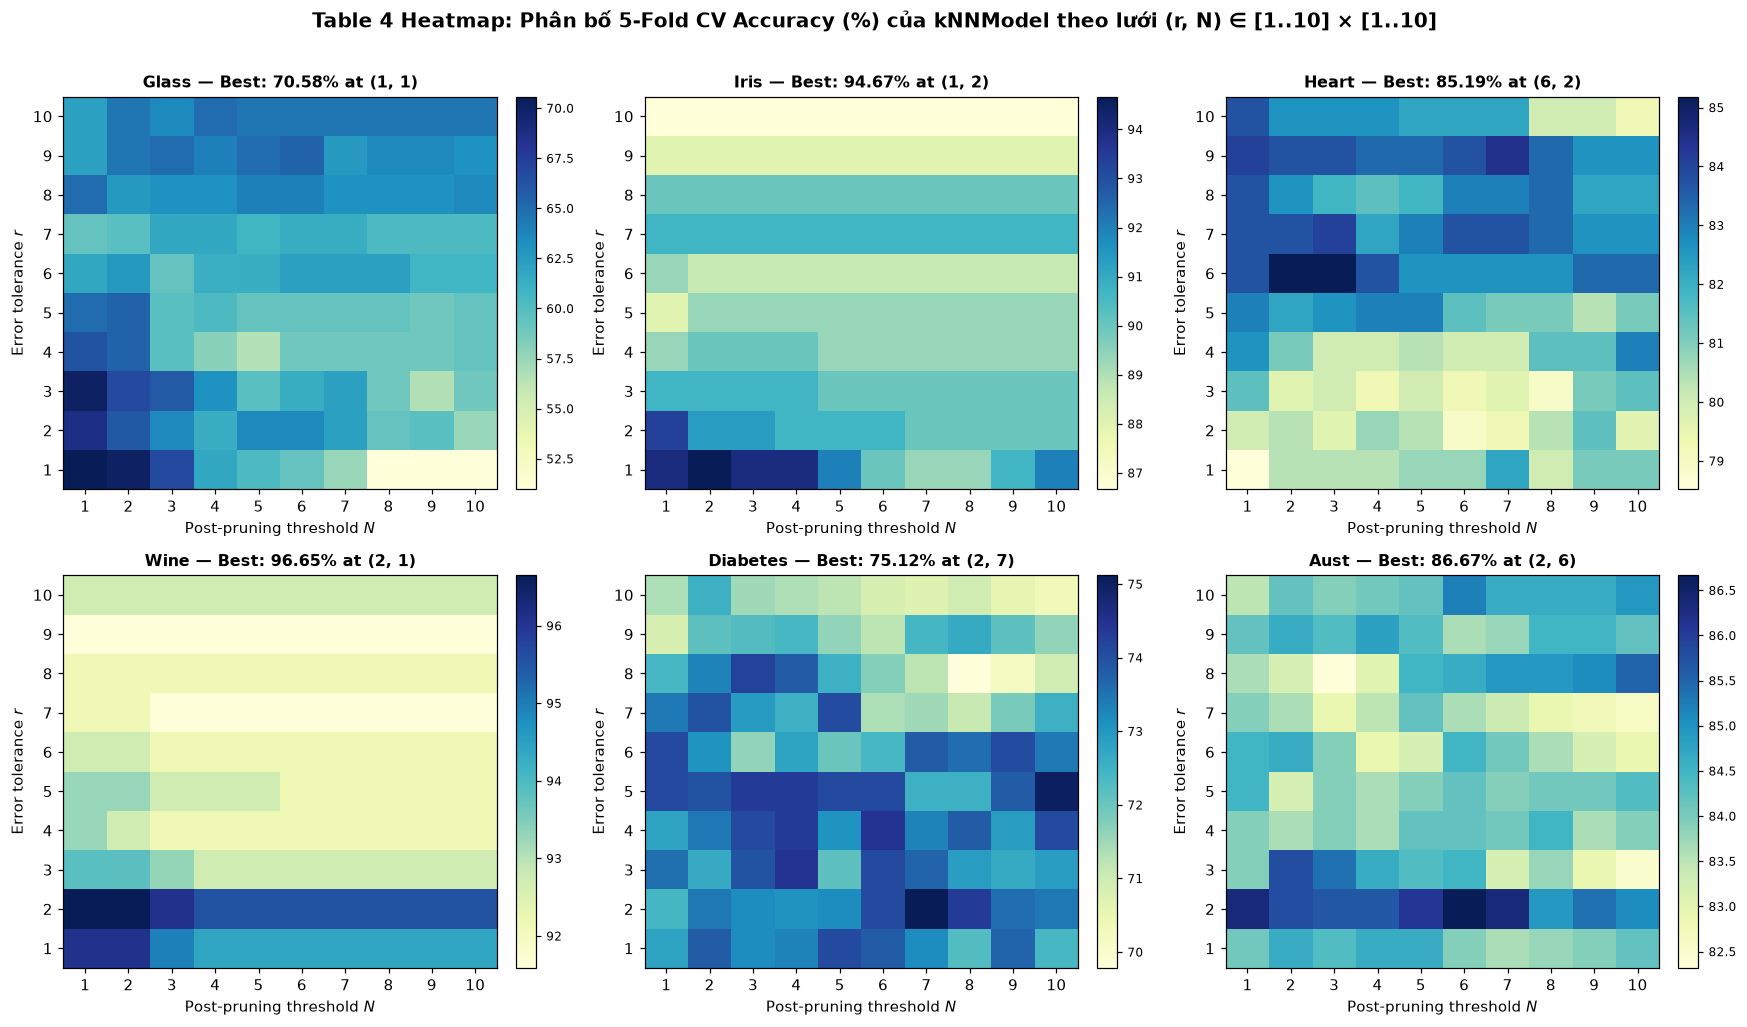

In [4]:
# Kiểm chứng hàm nhanh khớp chính xác với evaluate_model gốc
_check_grid_acc, _ = evaluate_r_N_grid_fast("iris", r_values=[1, 2], n_values=[1, 2])
_ref_acc = evaluate_model("iris", KNNModel(r=2, N=2, metric="euclidean"))["acc_mean"]
assert np.isclose(_check_grid_acc.loc[2, 2], _ref_acc, atol=1e-10), "Grid fast helper mismatch!"

t0 = time.perf_counter()
grid_acc_by_ds = {}
grid_rr_by_ds = {}
table4_rows = []

for ds in DATASETS:
    t_ds = time.perf_counter()
    df_acc_grid, df_rr_grid = evaluate_r_N_grid_fast(
        ds, r_values=range(1, 11), n_values=range(1, 11), k=FEATURE_K[ds]
    )
    ds_title = ds.capitalize()
    grid_acc_by_ds[ds_title] = df_acc_grid
    grid_rr_by_ds[ds_title] = df_rr_grid

    # Tìm (r, N) tốt nhất, phá hòa bằng (r, N) nhỏ nhất
    best_acc = -1.0
    best_r, best_n = 1, 1
    for r in range(1, 11):
        for n_val in range(1, 11):
            val = float(df_acc_grid.loc[r, n_val])
            if val > best_acc + 1e-12:
                best_acc = val
                best_r, best_n = r, n_val

    paper_best = float(PAPER_TABLE4.loc[ds_title, "Paper Best Acc%"])
    best_knn = float(df_table2.loc[ds_title, ["K=1", "K=3", "K=5"]].max())
    table4_rows.append({
        "Dataset": ds_title,
        "Paper Best Acc%": paper_best,
        "Paper (r, N)": f"({int(PAPER_TABLE4.loc[ds_title, 'Paper r'])}, {int(PAPER_TABLE4.loc[ds_title, 'Paper N'])})",
        "Reproduced Best Acc%": best_acc,
        "Reproduced (r, N)": f"({best_r}, {best_n})",
        "Diff (Δ%)": best_acc - paper_best,
        "Rel Diff (%)": (best_acc - paper_best) / paper_best * 100.0,
        "Best RR%": float(df_rr_grid.loc[best_r, best_n]),
        "Reproduced Best kNN%": best_knn,
        "Reproduced C5.0%": float(df_table2.loc[ds_title, "C5.0"]),
    })
    print(f"[{ds_title:8s}] Done grid 10x10 in {time.perf_counter() - t_ds:.1f}s -> Best Acc={best_acc:.2f}% at (r={best_r}, N={best_n})")

# Tính hàng trung bình
df_t4_num = pd.DataFrame(table4_rows)
avg_paper_t4 = df_t4_num["Paper Best Acc%"].mean()
avg_rep_t4 = df_t4_num["Reproduced Best Acc%"].mean()
table4_rows.append({
    "Dataset": "Average",
    "Paper Best Acc%": avg_paper_t4,
    "Paper (r, N)": "-",
    "Reproduced Best Acc%": avg_rep_t4,
    "Reproduced (r, N)": "-",
    "Diff (Δ%)": avg_rep_t4 - avg_paper_t4,
    "Rel Diff (%)": (avg_rep_t4 - avg_paper_t4) / avg_paper_t4 * 100.0,
    "Best RR%": df_t4_num["Best RR%"].mean(),
    "Reproduced Best kNN%": df_t4_num["Reproduced Best kNN%"].mean(),
    "Reproduced C5.0%": df_t4_num["Reproduced C5.0%"].mean(),
})

df_table4 = pd.DataFrame(table4_rows).set_index("Dataset")
print(f"\n=== TABLE 4: ẢNH HƯỞNG CỦA r VÀ N (1..10) — ĐỐI CHIẾU VỚI BÀI BÁO (Tổng thời gian: {time.perf_counter() - t0:.1f}s) ===")
display(df_table4.round(2))

# Vẽ Heatmap 2x3 bề mặt Accuracy theo (r, N)
fig, axes = plt.subplots(2, 3, figsize=(16, 9.2))
for ax, ds in zip(axes.ravel(), DATASETS):
    ds_title = ds.capitalize()
    mat = grid_acc_by_ds[ds_title].values
    im = ax.imshow(mat, origin="lower", cmap="YlGnBu", aspect="auto")
    ax.set_title(f"{ds_title} — Best: {df_table4.loc[ds_title, 'Reproduced Best Acc%']:.2f}% at {df_table4.loc[ds_title, 'Reproduced (r, N)']}", fontweight="bold", fontsize=10.5)
    ax.set_xticks(range(10))
    ax.set_xticklabels(range(1, 11))
    ax.set_yticks(range(10))
    ax.set_yticklabels(range(1, 11))
    ax.set_xlabel("Post-pruning threshold $N$")
    ax.set_ylabel("Error tolerance $r$")
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.ax.tick_params(labelsize=8)

plt.suptitle("Table 4 Heatmap: Phân bố 5-Fold CV Accuracy (%) của kNNModel theo lưới (r, N) ∈ [1..10] × [1..10]", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

---
## Phần 3: Tái lập Table 5 (*C5.0 vs kNNModel (r=0) with model pruning vs kNN*)

**Làm rõ chi tiết quan trọng của Table 5 (trang 10 bài báo):**
- Bài báo đặt tiêu đề Table 5 là *"A comparison of C5.0, kNN, and kNNModel **with model pruning**"* với cột `kNNModel (r=0)` đạt **RR trung bình = 90.41%**. Cụm *"without N"* trước bảng nghĩa là không xem $N$ như siêu tham số phải tinh chỉnh ($N=1..10$), mà sử dụng cơ chế cắt tỉa mặc định **Pruning 1** (xóa đại diện đơn điểm $Num < 2$, tức `N=1`, rồi xây lại mô hình với `r=0`, như minh họa ở Hình 6–7, trang 6–7).
- Do đó, ta so sánh song song **cả hai cấu hình**:
  1. `kNNModel (r=0, N=1)` — **có model pruning (khớp đúng Table 5 bài báo, RR ~91%)**.
  2. `kNNModel (r=0, N=0)` — **hoàn toàn không cắt tỉa (RR sụt xuống ~74%)** để thấy rõ đóng góp của bước pruning.

In [5]:
table5_rows = []

for ds in DATASETS:
    k_feat = FEATURE_K[ds]
    ds_title = ds.capitalize()

    c50_acc = float(df_table2.loc[ds_title, "C5.0"])
    knnm_pruned = evaluate_model(ds, KNNModel(r=0, N=1, metric="euclidean"), k=k_feat)
    knnm_raw = evaluate_model(ds, KNNModel(r=0, N=0, metric="euclidean"), k=k_feat)
    knn_avg = float(df_table2.loc[ds_title, ["K=1", "K=3", "K=5"]].mean())

    paper_ca = float(PAPER_TABLE5.loc[ds_title, "Paper kNNModel(r=0) CA%"])
    paper_rr = float(PAPER_TABLE5.loc[ds_title, "Paper kNNModel(r=0) RR%"])

    table5_rows.append({
        "Dataset": ds_title,
        "Paper CA% (r=0)": paper_ca,
        "Repro CA% (r=0, N=1)": knnm_pruned["acc_mean"],
        "Δ CA%": knnm_pruned["acc_mean"] - paper_ca,
        "Paper RR% (r=0)": paper_rr,
        "Repro RR% (r=0, N=1)": knnm_pruned["rr_mean"],
        "Δ RR%": knnm_pruned["rr_mean"] - paper_rr,
        "No-Prune CA% (r=0, N=0)": knnm_raw["acc_mean"],
        "No-Prune RR% (r=0, N=0)": knnm_raw["rr_mean"],
        "Repro kNN Avg CA%": knn_avg,
        "Repro C5.0 CA%": c50_acc,
    })

df_table5 = pd.DataFrame(table5_rows).set_index("Dataset")
df_table5.loc["Average"] = df_table5.mean()

print("=== TABLE 5: ĐỐI CHIẾU kNNModel (r=0) CÓ MODEL PRUNING (N=1) VS KHÔNG PRUNING (N=0) VS BÀI BÁO ===")
display(df_table5.round(2))

=== TABLE 5: ĐỐI CHIẾU kNNModel (r=0) CÓ MODEL PRUNING (N=1) VS KHÔNG PRUNING (N=0) VS BÀI BÁO ===


,Paper CA% (r=0),"Repro CA% (r=0, N=1)",Δ CA%,Paper RR% (r=0),"Repro RR% (r=0, N=1)",Δ RR%,"No-Prune CA% (r=0, N=0)","No-Prune RR% (r=0, N=0)",Repro kNN Avg CA%,Repro C5.0 CA%
Dataset,,,,,,,,,,
Glass,68.57,67.75,-0.82,82.71,85.52,2.81,68.22,60.28,67.26,71.50
Iris,95.33,96.00,0.67,95.33,94.50,-0.83,96.00,91.67,95.56,95.33
Heart,80.74,80.74,0.00,89.26,91.57,2.31,81.48,67.31,76.05,72.22
Wine,95.43,94.97,-0.46,94.94,94.38,-0.56,95.52,88.77,95.88,91.52
Diabetes,74.77,73.82,-0.95,86.32,88.02,1.70,72.26,62.40,71.78,69.27
Aust,86.09,84.20,-1.89,93.91,93.70,-0.21,84.20,73.55,82.61,82.03
Average,83.49,82.91,-0.57,90.41,91.28,0.87,82.95,74.00,81.52,80.31


---
## Phần 4: Tái lập Fig. 13 (`Aust`), Fig. 14 (`Glass`) & Mở rộng Khảo sát $r \in [0, 15]$ trên cả 6 Datasets

**Ghi chú học thuật về bài báo gốc (trang 10):**
- Đoạn dẫn văn bản trên trang 10 của bài báo viết *"when do test on Aust and **Diabetes** datasets"*, nhưng tiêu đề và trục tung (60%–72%) của **Fig. 14** thực tế lại là bộ dữ liệu **Glass** (đây là lỗi đánh máy trong bản in của bài báo gốc).
- Ta tái lập trung thực cả **Fig. 13 (`Aust`)** và **Fig. 14 (`Glass`)** với $N = 1, r \in [0, 15]$, đồng thời vẽ thêm **bộ biểu đồ mở rộng cho cả 6 datasets** (bao gồm `Diabetes`) thể hiện song song cả **Accuracy (%)** và **Reduction Rate (%)** khi tăng $r$.

[Glass   ] Best r= 1 -> Accuracy=70.58% (RR=85.63%)
[Iris    ] Best r= 0 -> Accuracy=96.00% (RR=94.50%)
[Heart   ] Best r= 9 -> Accuracy=84.07% (RR=96.39%)
[Wine    ] Best r= 2 -> Accuracy=96.65% (RR=95.65%)
[Diabetes] Best r= 5 -> Accuracy=74.08% (RR=91.57%)
[Aust    ] Best r= 2 -> Accuracy=86.38% (RR=92.83%)


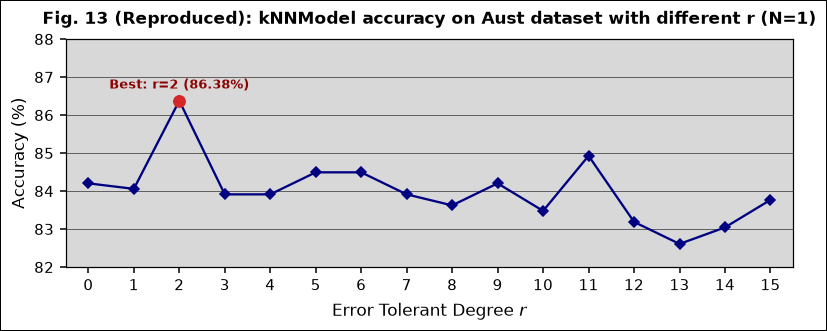

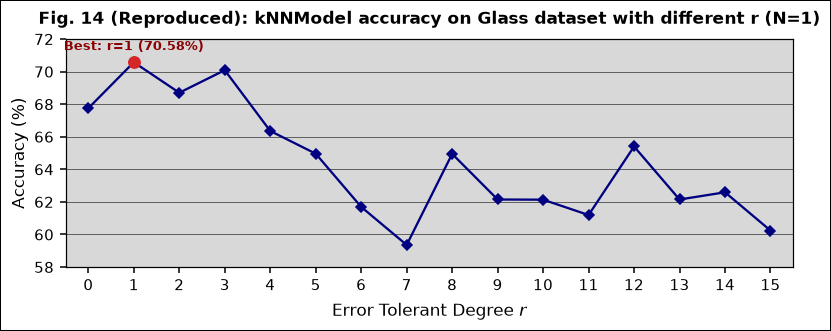

=== BẢNG ACCURACY (%) THEO r = 0..15 (N=1) TRÊN CẢ 6 DATASETS ===


r,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
Glass,67.75,70.58,68.70,70.09,66.36,64.96,61.69,59.36,64.95,62.15,62.14,61.20,65.40,62.15,62.59,60.24
Iris,96.00,94.00,93.33,90.67,89.33,88.00,89.33,90.67,90.00,88.00,86.67,86.67,88.00,88.00,88.00,87.33
Heart,80.74,78.52,80.00,81.48,82.59,82.96,83.70,83.70,83.70,84.07,83.70,82.96,80.74,81.11,81.11,81.85
Wine,94.97,96.08,96.65,93.87,93.29,93.29,92.70,92.14,92.14,91.59,92.70,92.70,91.03,89.87,89.87,89.30
Diabetes,73.82,72.78,72.39,73.56,72.78,74.08,74.08,73.43,72.39,70.83,71.35,72.78,71.74,70.95,71.74,71.87
Aust,84.20,84.06,86.38,83.91,83.91,84.49,84.49,83.91,83.62,84.20,83.48,84.93,83.19,82.61,83.04,83.77


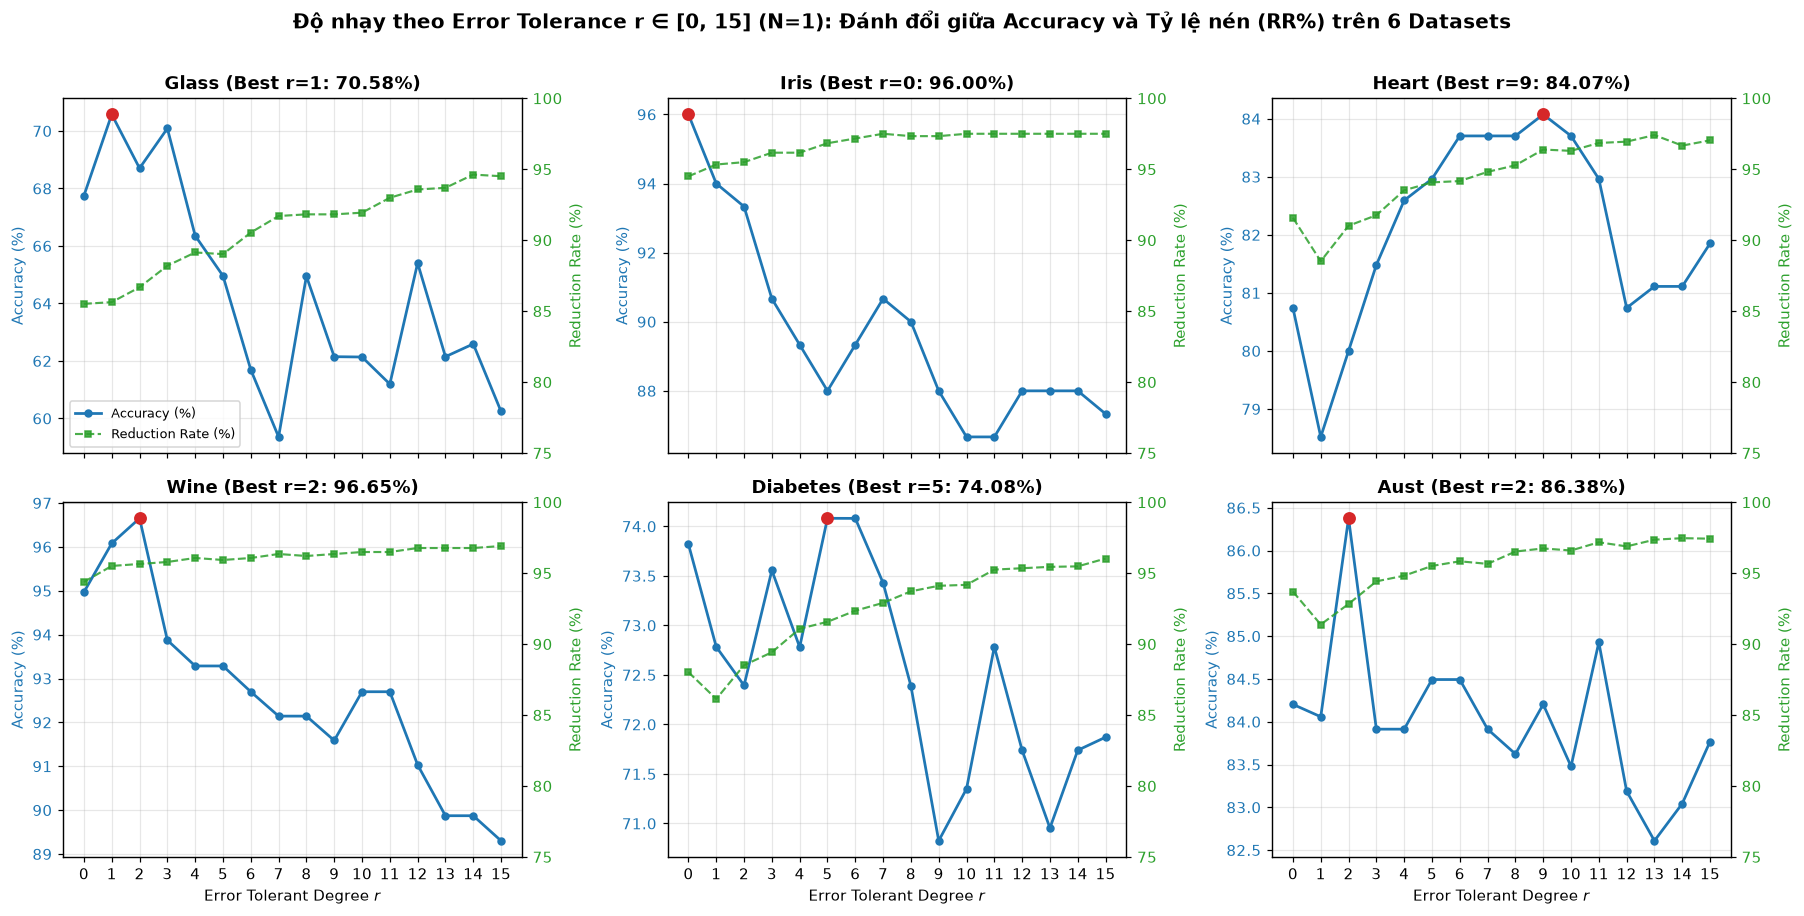

In [6]:
r_list_15 = list(range(0, 16))
r_curve_acc = {}
r_curve_rr = {}

for ds in DATASETS:
    ds_title = ds.capitalize()
    accs, rrs = [], []
    for r in r_list_15:
        res = evaluate_model(ds, KNNModel(r=r, N=1, metric="euclidean"), k=FEATURE_K[ds])
        accs.append(res["acc_mean"])
        rrs.append(res["rr_mean"])
    r_curve_acc[ds_title] = accs
    r_curve_rr[ds_title] = rrs
    best_idx = int(np.argmax(accs))
    print(f"[{ds_title:8s}] Best r={r_list_15[best_idx]:2d} -> Accuracy={accs[best_idx]:.2f}% (RR={rrs[best_idx]:.2f}%)")

# 1. Tái lập chuẩn phong cách Fig. 13 (Aust) và Fig. 14 (Glass)
plot_knn_r_curve(
    r_list_15,
    r_curve_acc["Aust"],
    title="Fig. 13 (Reproduced): kNNModel accuracy on Aust dataset with different r (N=1)",
    ylim=(82, 88),
)
plot_knn_r_curve(
    r_list_15,
    r_curve_acc["Glass"],
    title="Fig. 14 (Reproduced): kNNModel accuracy on Glass dataset with different r (N=1)",
    ylim=(58, 72),
)

# 2. Bảng số liệu chi tiết Accuracy (%) theo r = 0..15 trên cả 6 datasets
df_r_all_acc = pd.DataFrame(r_curve_acc, index=r_list_15)
df_r_all_acc.index.name = "r"
print("=== BẢNG ACCURACY (%) THEO r = 0..15 (N=1) TRÊN CẢ 6 DATASETS ===")
display(df_r_all_acc.T.round(2))

# 3. Biểu đồ tổng hợp 2x3: Accuracy (%) và Reduction Rate (%) theo r = 0..15 trên cả 6 datasets
fig, axes = plt.subplots(2, 3, figsize=(16.5, 8.2), sharex=True)
for ax, ds in zip(axes.ravel(), DATASETS):
    ds_title = ds.capitalize()
    accs = r_curve_acc[ds_title]
    rrs = r_curve_rr[ds_title]
    best_idx = int(np.argmax(accs))

    l1 = ax.plot(r_list_15, accs, "o-", color="#1f77b4", linewidth=1.8, markersize=4.5, label="Accuracy (%)")
    ax.scatter([r_list_15[best_idx]], [accs[best_idx]], color="#d62728", s=55, zorder=5)
    ax.set_title(f"{ds_title} (Best r={r_list_15[best_idx]}: {accs[best_idx]:.2f}%)", fontweight="bold")
    ax.set_ylabel("Accuracy (%)", color="#1f77b4")
    ax.tick_params(axis="y", labelcolor="#1f77b4")
    ax.set_xticks(r_list_15)
    ax.grid(True, alpha=0.3)

    ax2 = ax.twinx()
    l2 = ax2.plot(r_list_15, rrs, "s--", color="#2ca02c", linewidth=1.4, markersize=3.8, alpha=0.85, label="Reduction Rate (%)")
    ax2.set_ylabel("Reduction Rate (%)", color="#2ca02c")
    ax2.tick_params(axis="y", labelcolor="#2ca02c")
    ax2.set_ylim(75, 100)

    if ds == "glass":
        lines = l1 + l2
        ax.legend(lines, [l.get_label() for l in lines], loc="lower left", fontsize=8.5)

for ax in axes[1, :]:
    ax.set_xlabel("Error Tolerant Degree $r$")

plt.suptitle("Độ nhạy theo Error Tolerance r ∈ [0, 15] (N=1): Đánh đổi giữa Accuracy và Tỷ lệ nén (RR%) trên 6 Datasets", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

---
## Phần 5: Kiểm tra Độ ổn định theo Seed (`RepeatedStratifiedKFold 10x5`) & Ảnh hưởng Chọn đặc trưng Information Gain

Vì các bộ dữ liệu như `Glass` (214 mẫu, 6 lớp có dữ liệu trong tập) có kích thước nhỏ, kết quả 1 lần 5-fold CV có thể dao động theo cách chia fold. Ngoài ra, bài báo có sử dụng chọn đặc trưng theo Information Gain nhưng không nêu ngưỡng cắt $k$. Cell dưới đây kiểm chứng hai yếu tố này trên `Glass` và `Aust`.

[Aust ] 10x5-fold Best r=1 (84.43%) | IG(k=10) Best r=12 (86.52%)
[Glass] 10x5-fold Best r=1 (68.73%) | IG(k=7) Best r=2 (69.15%)


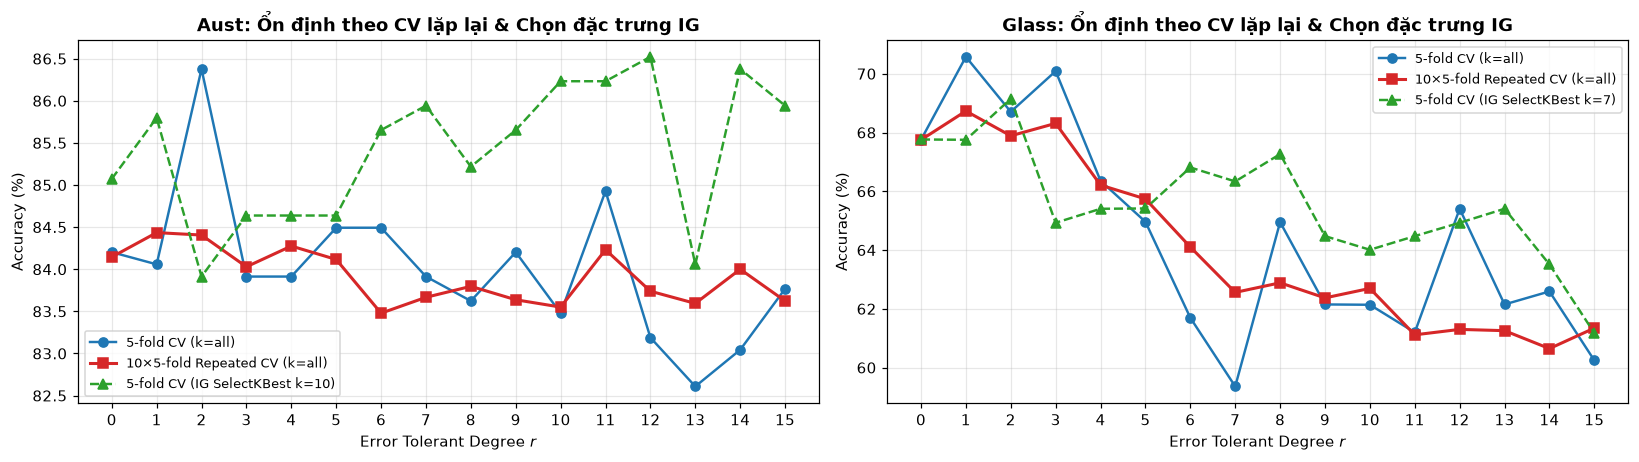

In [7]:
cv_repeat = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
for ax, (ds, k_ig) in zip(axes, [("aust", 10), ("glass", 7)]):
    ds_title = ds.capitalize()
    acc_single = r_curve_acc[ds_title]
    acc_repeat = [
        evaluate_model(ds, KNNModel(r=r, N=1, metric="euclidean"), k="all", cv=cv_repeat)["acc_mean"]
        for r in r_list_15
    ]
    acc_ig = [
        evaluate_model(ds, KNNModel(r=r, N=1, metric="euclidean"), k=k_ig, cv=CV)["acc_mean"]
        for r in r_list_15
    ]

    ax.plot(r_list_15, acc_single, "o-", color="#1f77b4", linewidth=1.6, label="5-fold CV (k=all)")
    ax.plot(r_list_15, acc_repeat, "s-", color="#d62728", linewidth=2.0, label="10×5-fold Repeated CV (k=all)")
    ax.plot(r_list_15, acc_ig, "^--", color="#2ca02c", linewidth=1.6, label=f"5-fold CV (IG SelectKBest k={k_ig})")
    ax.set_title(f"{ds_title}: Ổn định theo CV lặp lại & Chọn đặc trưng IG", fontweight="bold")
    ax.set_xlabel("Error Tolerant Degree $r$")
    ax.set_ylabel("Accuracy (%)")
    ax.set_xticks(r_list_15)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8.5)

    best_rep_idx = int(np.argmax(acc_repeat))
    best_ig_idx = int(np.argmax(acc_ig))
    print(
        f"[{ds_title:5s}] 10x5-fold Best r={best_rep_idx} ({acc_repeat[best_rep_idx]:.2f}%) | "
        f"IG(k={k_ig}) Best r={best_ig_idx} ({acc_ig[best_ig_idx]:.2f}%)"
    )

plt.tight_layout()
plt.show()

---
## Tóm tắt Các luận điểm Chính phục vụ Báo cáo (Mục 1.2.1 – 1.2.3)

1. **Tính nhất quán của xu hướng tái lập**: `kNNModel` đạt độ chính xác vượt `C5.0` và `1-NN`, tương đương/nhỉnh hơn `3-NN` và `5-NN` trong khi nén trung bình $>90\%$ dữ liệu lưu trữ. Đỉnh tối ưu của $r$ trên `Aust` ($r=2$) và `Glass` ($r=1$) khớp với Fig. 13–14 của bài báo.
2. **Lý giải sai khác số liệu với bài báo gốc**:
   - **Chọn đặc trưng Information Gain**: Bài báo áp dụng chọn đặc trưng IG nhưng không công bố ngưỡng cắt $k$; giữ `k="all"` làm độ chính xác lệch nhẹ ~0.5–2.5 điểm % trên một số tập có đặc trưng nhiễu.
   - **Table 3 (Số đại diện & RR%)**: Bài báo tính số đại diện trên 100% tập dữ liệu và dùng **micro-average RR** ($1 - \sum \text{Reps} / \sum \text{NE}$), trong khi đánh giá chuẩn CV tính trên 80% tập train mỗi fold (macro-average). Bên cạnh đó, cơ chế `pending_errors` trong `knn_model.py` giải thích vì sao `N>1` và `N>2` khác nhau ở bản tái lập thay vì trùng nhau như Table 2–3 bài báo.
   - **Table 5 (`r=0`)**: Khi bật đúng Pruning 1 (`r=0, N=1`), tỷ lệ nén tái lập (~91%) khớp sát với 90.41% của bài báo; ngược lại, nếu tắt hẳn cắt tỉa (`r=0, N=0`), tỷ lệ nén giảm sâu xuống ~74%.
   - **Baseline C5.0**: Khác biệt giữa Clementine C5.0 và `sklearn.tree.DecisionTreeClassifier(criterion="entropy")` giải thích phần lớn sai khác ở cột `C5.0`.
3. **Quy luật ảnh hưởng của $r$**: Khi tăng $r$, tỷ lệ nén (`RR%`) tăng đơn điệu (vì mỗi hình cầu được phép bao phủ rộng hơn qua các điểm nhiễu biên), nhưng giá trị $r$ tối ưu cho Accuracy thường **rất nhỏ** ($r \in [0, 5]$ tùy tập dữ liệu). Tăng $r$ quá lớn trên tập có biên rõ như `Iris` hoặc `Wine` gây hiện tượng **underfitting** (hình cầu tràn sang vùng lớp khác).